In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.applications import Xception, MobileNetV2
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.datasets import cifar10

import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

tf.random.set_seed(42)
np.random.seed(42)

In [ ]:
print("Loading cifar-10 dataset....")
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

y_train_categorical = to_categorical(y_train, 10)
y_test_categorical = to_categorical(y_test, 10)

print(f"Training data shape: {x_train.shape}")
print(f"Training labels shape: {y_train_categorical.shape}")
print(f"Test data shape: {x_test.shape}")

Loading cifar-10 dataset....
170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 17s 0us/step
Training data shape: (50000, 32, 32, 3)
Training labels shape: (50000, 10)
Test data shape: (10000, 32, 32, 3)


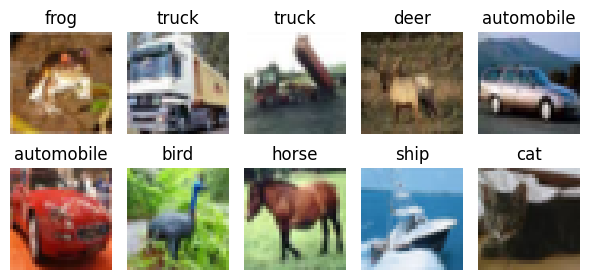

In [ ]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

def show_sample_images(x, y, class_names, num_samples=10):
    plt.figure(figsize=(6, 3))
    for i in range(num_samples):
      plt.subplot(2, 5, i + 1)
      plt.imshow(x[i])
      label = y[i] if np.ndim(y) == 1 else y[i][0]
      plt.title(f"{class_names[label]}")
      plt.axis("off")
    plt.tight_layout()
    plt.show()

show_sample_images(x_train, y_train, class_names)

In [ ]:
def resize_images(images,target_size=(75, 75)):
  return tf.image.resize(images, target_size)

print("Resizing images....")
x_train_resized = resize_images(x_train, (75, 75))
x_test_resized = resize_images(x_test, (75,75))

print(f"Resized training data shape: {x_train_resized.shape}")
print(f"Resized test data shape: {x_test_resized.shape}")

Resizing images....
Resized training data shape: (50000, 75, 75, 3)
Resized test data shape: (10000, 75, 75, 3)


In [ ]:
def create_xception_model(input_shape=(75, 75, 3), num_classes=10):
  base_model = Xception(weights='imagenet', include_top=False,
  input_shape=input_shape, pooling='avg')
  base_model.trainable = False

  model = models.Sequential([
      base_model,
      layers.Dropout(0.5),
      layers.Dense(512, activation='relu'),
      layers.BatchNormalization(),
      layers.Dropout(0.3),
      layers.Dense(256, activation='relu'),
      layers.Dropout(0.2),
      layers.Dense(num_classes, activation='softmax')
  ])

  return model
xception_model = create_xception_model()
xception_model.compile(optimizer=Adam(1e-4), loss='categorical_crossentropy', metrics=['accuracy'])

print("Xception model summary:")
xception_model.summary()

Xception model summary:


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ xception (Functional)           │ (None, 2048)           │    20,861,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,046,514 (84.10 MB)

 Trainable params: 1,184,010 (4.52 MB)

 Non-trainable params: 20,862,504 (79.58 MB)

In [ ]:
xception_callbacks = [
    EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss',factor=0.2, patience=5, min_lr=1e-7, verboose=1)
]

In [ ]:
#Train the model:

print("Training Xception model....")
xception_history = xception_model.fit(
x_train_resized, y_train_categorical,
batch_size=64,
epochs=30,
validation_split=0.2,
callbacks=xception_callbacks,
verbose=1
)

Training Xception model....
Epoch 1/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 27s 43ms/step - accuracy: 0.7684 - loss: 0.6566 - val_accuracy: 0.7529 - val_loss: 0.7075 - learning_rate: 1.0000e-04
Epoch 2/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 27s 43ms/step - accuracy: 0.7673 - loss: 0.6492 - val_accuracy: 0.7539 - val_loss: 0.7079 - learning_rate: 1.0000e-04
Epoch 3/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 27s 43ms/step - accuracy: 0.7711 - loss: 0.6415 - val_accuracy: 0.7505 - val_loss: 0.7078 - learning_rate: 1.0000e-04
Epoch 4/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 27s 43ms/step - accuracy: 0.7724 - loss: 0.6364 - val_accuracy: 0.7520 - val_loss: 0.7048 - learning_rate: 1.0000e-04
Epoch 5/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 27s 43ms/step - accuracy: 0.7755 - loss: 0.6292 - val_accuracy: 0.7512 - val_loss: 0.7080 - learning_rate: 1.0000e-04
Epoch 6/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 27s 43ms/step - accuracy: 0.7771 - loss: 0.6254 - val_accuracy: 0.7514 - val_loss: 0.7086 - learning_rate: 1.0000e-04
Epoch 7/30
625/625 ━━━━━

313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.7535 - loss: 0.7085
Xception Test Loss: 0.7085
Xception Test Accuracy: 0.7535


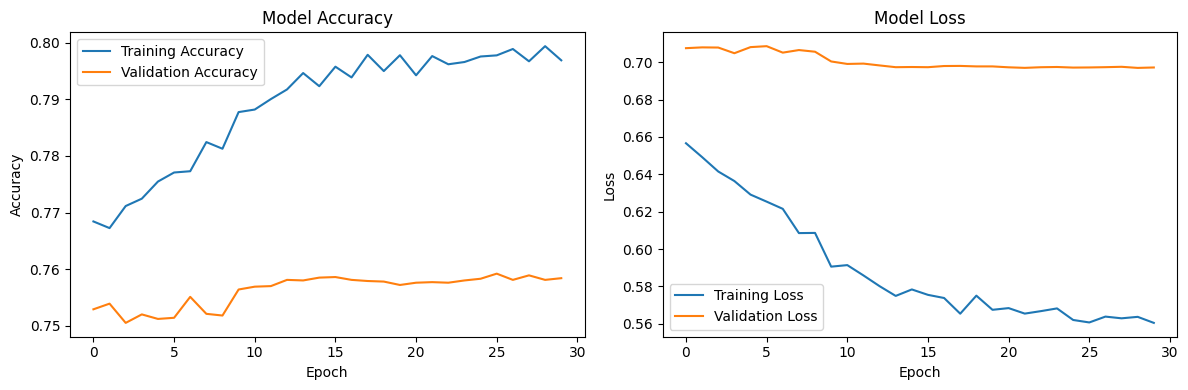

In [ ]:
#Evaluating the model:
xception_test_loss, xception_test_accuracy = xception_model.evaluate(x_test_resized, y_test_categorical)
print(f"Xception Test Loss: {xception_test_loss:.4f}")
print(f"Xception Test Accuracy: {xception_test_accuracy:.4f}")

plt.figure(figsize=(12,4))

plt.subplot(1, 2, 1)
plt.plot(xception_history.history['accuracy'], label='Training Accuracy')
plt.plot(xception_history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(xception_history.history['loss'], label='Training Loss')
plt.plot(xception_history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
#MobileNetV2 Model:

def create_mobilenetv2_model(input_shaape=(75,75,3), num_classes=10):
  base_model = MobileNetV2(weights='imagenet', include_top=False,
  input_shape=input_shape, pooling='avg')
  base_model.trainable = False

  model = models.Sequential([
      base_model,
      layers.Droupout(0.4),
      layers.Dense(512, activation='relu'),
      layers.BatchNormalization(),
      layers.Dropout(0.3),
      layers.Dense(256, activation='relu'),
      layers.Dropout(0.2),
      layers.Dense(num_classes, activation='softmax')
  ])
  return model

mobilenet_model = create_mobilenetv2_model()
mobilenet_model.compile(optimizer=Adam(1e-4), loss='categorical_crossentropy', metrics=['accuracy'])

print("MobileNetV2 model summary:")
mobilenet_model.summary()

mobilenet_callbacks = [
EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True, verbose=1),
ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5, min_lr=1e-7, verbose=1)
]

print("Training")
